In [ ]:
from google.colab import files

uploaded = files.upload()

Saving EEG Eye State.csv to EEG Eye State.csv


In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import classification_report, confusion_matrix

# Load dataset
file_path = '/content/EEG Eye State.csv'
df = pd.read_csv(file_path)

# Separate features and target
X = df.drop("eyeDetection", axis=1)
y = df["eyeDetection"]

# Standardize features (important for K-means)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-means clustering
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# Map clusters to actual classes (since K-means is unsupervised, clusters may not match labels)
# We decide which cluster corresponds to which class based on majority voting
import numpy as np

mapped_clusters = np.where(
    clusters == 0,
    1 if np.mean(y[clusters == 0]) > 0.5 else 0,
    1 if np.mean(y[clusters == 1]) > 0.5 else 0
)

# Evaluate clustering performance
print("Confusion Matrix:")
print(confusion_matrix(y, mapped_clusters))

print("\nClassification Report:")
print(classification_report(y, mapped_clusters))

Confusion Matrix:
[[8257    0]
 [6722    1]]

Classification Report:
              precision    recall  f1-score   support

           0       0.55      1.00      0.71      8257
           1       1.00      0.00      0.00      6723

    accuracy                           0.55     14980
   macro avg       0.78      0.50      0.36     14980
weighted avg       0.75      0.55      0.39     14980



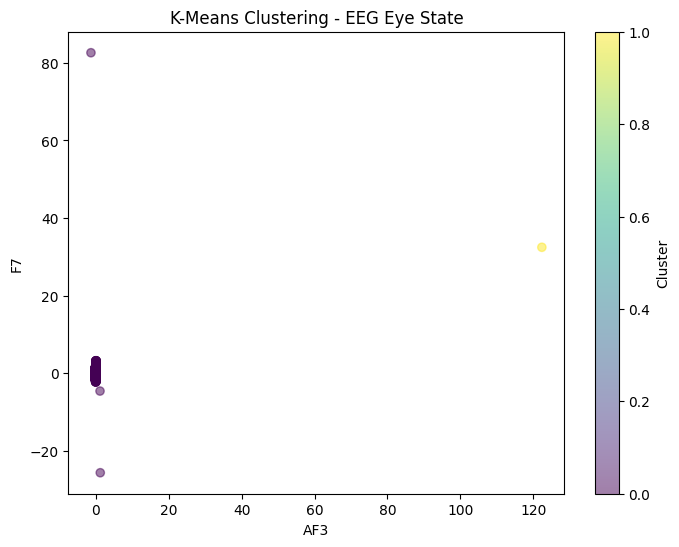

In [ ]:
# ========================================
# SCATTER PLOT
# ========================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap='viridis',
    alpha=0.5
)

plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.title("K-Means Clustering - EEG Eye State")
plt.colorbar(label="Cluster")

plt.show()